# PW3 — Exercise 2: News Classification
**Group 2 · Artificial Intelligence II**

In [1]:
import os
os.environ["PYTHONHASHSEED"] = str(42)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CUDNN_DETERMINISTIC"] = "1"

!pip install -q keras-tuner contractions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re, html, string, os, gc, time, random
from collections import Counter
from contractions import fix as expand_contractions

import torch
import torch.nn as nn

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import keras_tuner as kt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, precision_score, recall_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

gpus = tf.config.list_physical_devices('GPU')
print(f'TensorFlow : {tf.__version__}')
print(f'Keras Tuner: {kt.__version__}')
print(f'GPUs found : {len(gpus)}')
if gpus:    print(f'GPU name   : {gpus[0].name}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 15.8 MB/s eta 0:00:00
TensorFlow : 2.20.0
Keras Tuner: 1.4.8
GPUs found : 1
GPU name   : /physical_device:GPU:0


# **EDA**

In [ ]:
dataset = pd.read_csv('news_dataset.csv')
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Class Index  120000 non-null  int64 
 1   Title        120000 non-null  object
 2   Description  120000 non-null  object
dtypes: int64(1), object(2)
memory usage: 2.7+ MB


In [3]:
dataset.head(10)

,Class Index,Title,Description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."
5,3,"Stocks End Up, But Near Year Lows (Reuters)",Reuters - Stocks ended slightly higher on Frid...
6,3,Money Funds Fell in Latest Week (AP),AP - Assets of the nation's retail money marke...
7,3,Fed minutes show dissent over inflation (USATO...,USATODAY.com - Retail sales bounced back a bit...
8,3,Safety Net (Forbes.com),Forbes.com - After earning a PH.D. in Sociolog...
9,3,Wall St. Bears Claw Back Into the Black,"NEW YORK (Reuters) - Short-sellers, Wall Stre..."


In [4]:
for class_idx in sorted(dataset['Class Index'].unique()):
    print(f"\n{'='*60}")
    print(f"  CLASS INDEX: {class_idx}")
    print(f"{'='*60}")
    samples = dataset[dataset['Class Index'] == class_idx].head(5)
    for _, row in samples.iterrows():
        print(f"\n  Title      : {row['Title']}")
        print(f"  Description: {row['Description'][:150]}...")


  CLASS INDEX: 1

  Title      : Venezuelans Vote Early in Referendum on Chavez Rule (Reuters)
  Description: Reuters - Venezuelans turned out early\and in large numbers on Sunday to vote in a historic referendum\that will either remove left-wing President Hug...

  Title      : S.Koreans Clash with Police on Iraq Troop Dispatch (Reuters)
  Description: Reuters - South Korean police used water cannon in\central Seoul Sunday to disperse at least 7,000 protesters\urging the government to reverse a contr...

  Title      : Palestinians in Israeli Jails Start Hunger Strike (Reuters)
  Description: Reuters - Thousands of Palestinian\prisoners in Israeli jails began a hunger strike for better\conditions Sunday, but Israel's security minister said ...

  Title      : Seven Georgian soldiers wounded as South Ossetia ceasefire violated (AFP)
  Description: AFP - Sporadic gunfire and shelling took place overnight in the disputed Georgian region of South Ossetia in violation of a fragile ceasefi

In [5]:
# Based on sample inspection:
# 1 → World (international politics, conflicts, elections)
# 2 → Sports (Olympic games, NBA, baseball, football)
# 3 → Business (stock market, oil prices, finance)
# 4 → Sci/Tech (technology companies, software, electronics)

CLASS_NAMES = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Sci/Tech'}
COLORS      = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
dataset['category'] = dataset['Class Index'].map(CLASS_NAMES)
dataset['label']    = dataset['Class Index'] - 1
dataset['text']     = dataset['Title'] + ' ' + dataset['Description']

print(dataset['category'].value_counts())

category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


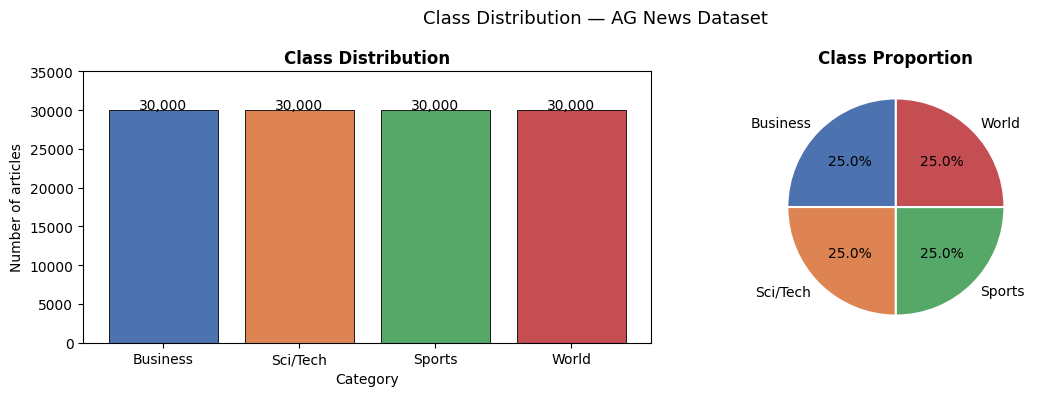

In [6]:
counts = dataset['category'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(counts.index, counts.values,
            color=COLORS, edgecolor='black', linewidth=0.6)
axes[0].set_title('Class Distribution', fontweight='bold')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Number of articles')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 200, f'{v:,}', ha='center', fontsize=10)
axes[0].set_ylim(0, 35000)

axes[1].pie(counts.values, labels=counts.index,
            colors=COLORS, autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Class Proportion', fontweight='bold')

plt.suptitle('Class Distribution — AG News Dataset', fontsize=13)
plt.tight_layout()
plt.show()

In [7]:
for col in ['Title', 'Description']:
    print(f"\n=== Duplicate {col} per class ===")
    for class_idx, class_name in CLASS_NAMES.items():
        subset = dataset[dataset['Class Index'] == class_idx]
        dupes = subset[col].duplicated().sum()
        print(f"  {class_name:10s}: {dupes:,} duplicates ({dupes/len(subset)*100:.2f}%)")


=== Duplicate Title per class ===
  World     : 996 duplicates (3.32%)
  Sports    : 788 duplicates (2.63%)
  Business  : 1,431 duplicates (4.77%)
  Sci/Tech  : 1,837 duplicates (6.12%)

=== Duplicate Description per class ===
  World     : 222 duplicates (0.74%)
  Sports    : 163 duplicates (0.54%)
  Business  : 354 duplicates (1.18%)
  Sci/Tech  : 440 duplicates (1.47%)


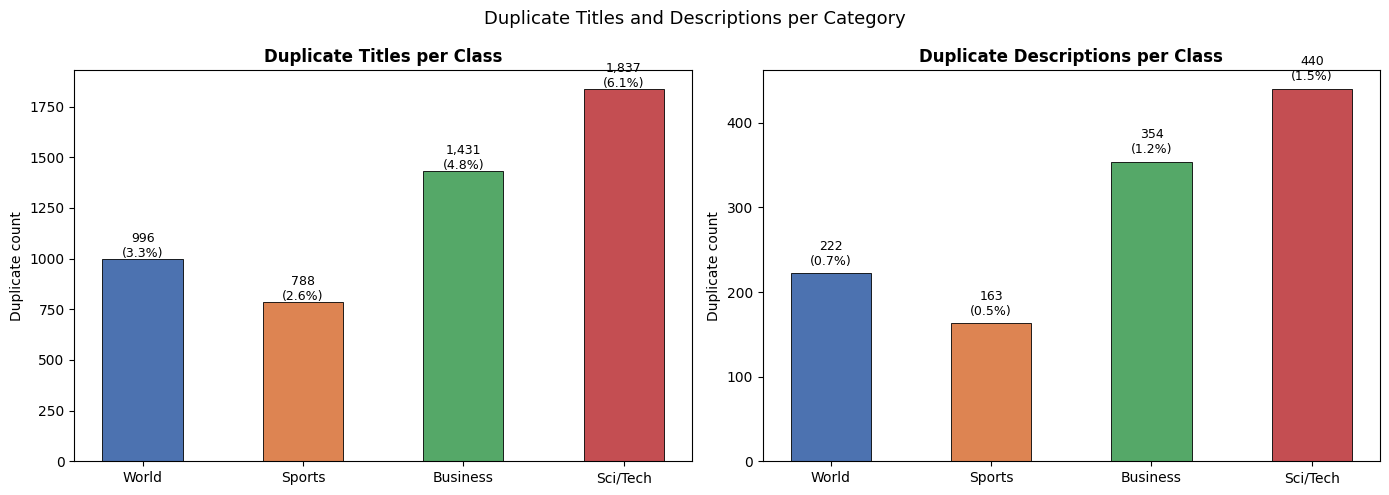

In [8]:
categories = list(CLASS_NAMES.values())

title_dupes = [dataset[dataset['Class Index'] == i]['Title'].duplicated().sum() for i in range(1,5)]
desc_dupes  = [dataset[dataset['Class Index'] == i]['Description'].duplicated().sum() for i in range(1,5)]

x = np.arange(len(categories))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, label in zip(axes, [title_dupes, desc_dupes], ['Title', 'Description']):
    bars = ax.bar(x, data, width=0.5, color=COLORS, edgecolor='black', linewidth=0.6)
    ax.set_title(f'Duplicate {label}s per Class', fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    ax.set_ylabel('Duplicate count')
    for bar, val in zip(bars, data):
        pct = val / 30000 * 100
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                f'{val:,}\n({pct:.1f}%)', ha='center', fontsize=9)

plt.suptitle('Duplicate Titles and Descriptions per Category', fontsize=13)
plt.tight_layout()
plt.show()

In [9]:
for col in ['Title', 'Description']:
    cross = dataset[dataset.duplicated(subset=[col], keep=False)]
    cross_diff_class = cross.groupby(col).filter(lambda x: x['Class Index'].nunique() > 1)

    print(f"\n=== {col} repeated across different classes ===")
    print(f"  Total cases : {len(cross_diff_class):,}")
    print(f"  Unique texts: {cross_diff_class[col].nunique():,}")

    pairs = Counter()
    for _, group in cross_diff_class.groupby(col):
        classes = sorted(group['Class Index'].unique())
        for i in range(len(classes)):
            for j in range(i+1, len(classes)):
                pairs[(CLASS_NAMES[classes[i]], CLASS_NAMES[classes[j]])] += 1
    print(f"  Distribution by class pair:")
    for (c1, c2), count in pairs.most_common():
        print(f"    {c1:10s} ↔ {c2:10s} : {count:,}")


=== Title repeated across different classes ===
  Total cases : 1,363
  Unique texts: 594
  Distribution by class pair:
    Business   ↔ Sci/Tech   : 377
    World      ↔ Business   : 98
    World      ↔ Sci/Tech   : 72
    World      ↔ Sports     : 41
    Sports     ↔ Business   : 8
    Sports     ↔ Sci/Tech   : 6

=== Description repeated across different classes ===
  Total cases : 243
  Unique texts: 98
  Distribution by class pair:
    Business   ↔ Sci/Tech   : 47
    World      ↔ Sci/Tech   : 23
    World      ↔ Business   : 21
    World      ↔ Sports     : 7


Text length analysis per category

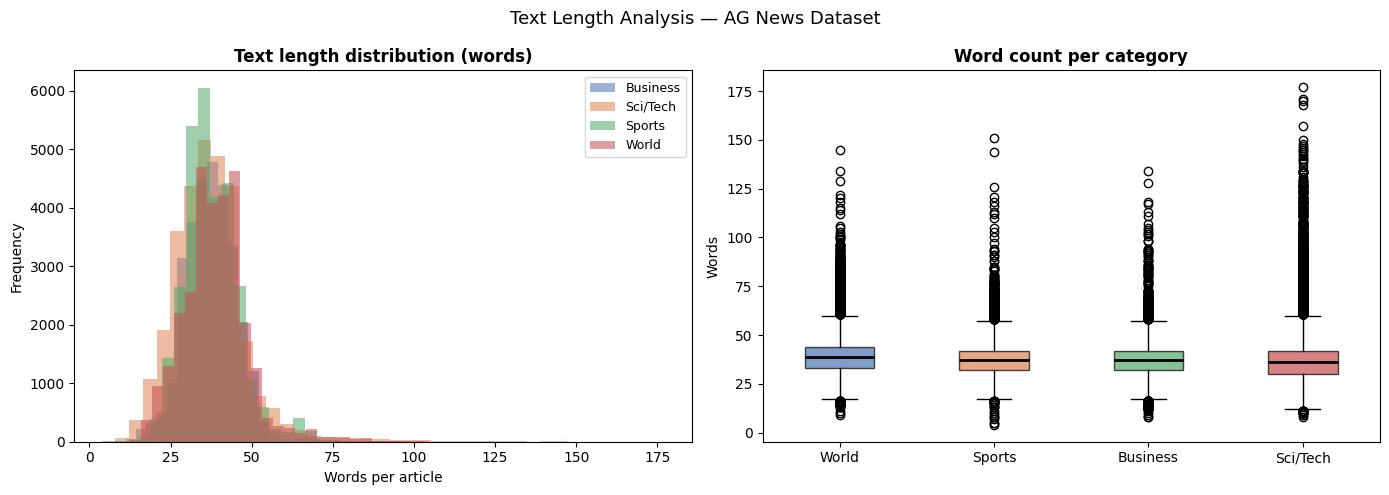

Word count statistics:
count    120000.0
mean         37.8
std          10.1
min           4.0
25%          32.0
50%          37.0
75%          43.0
max         177.0


In [10]:
dataset['title_len'] = dataset['Title'].str.split().str.len()
dataset['desc_len']  = dataset['Description'].str.split().str.len()
dataset['word_count'] = dataset['text'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, (cat, grp) in enumerate(dataset.groupby('category')):
    axes[0].hist(grp['word_count'], bins=40, alpha=0.55,
                 label=cat, color=COLORS[i], edgecolor='none')
axes[0].set_title('Text length distribution (words)', fontweight='bold')
axes[0].set_xlabel('Words per article')
axes[0].set_ylabel('Frequency')
axes[0].legend(fontsize=9)

data_box = [dataset[dataset['category'] == c]['word_count'].values for c in CLASS_NAMES.values()]
bp = axes[1].boxplot(data_box, patch_artist=True,
                     medianprops={'color': 'black', 'linewidth': 2})
for patch, color in zip(bp['boxes'], COLORS):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[1].set_xticklabels(list(CLASS_NAMES.values()))
axes[1].set_title('Word count per category', fontweight='bold')
axes[1].set_ylabel('Words')

plt.suptitle('Text Length Analysis — AG News Dataset', fontsize=13)
plt.tight_layout()
plt.show()

print(f"Word count statistics:")
print(dataset['word_count'].describe().round(1).to_string())

# **DATA CLEANING**

The cleaning pipeline mirrors Exercise 1 exactly for consistency. The only difference is that **stopwords are kept** in Exercise 2 because LSTM, GRU and Transformer gates use them for syntactic context — negations, conjunctions, and prepositions affect sentence meaning and help the model learn grammatical structure. They were removed in Exercise 1 because Skip-Gram context windows benefit from semantic purity.

In [11]:
dataset['text_clean'] = dataset['text'].apply(html.unescape)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black (Reute...
1    Carlyle Looks Toward Commercial Aerospace (Reu...
2    Oil and Economy Cloud Stocks' Outlook (Reuters...


Removes numeric HTML character references like &#160; or #39; — these are encoding artifacts from web scraping with no semantic content.

In [12]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'#\d+;', '', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black (Reute...
1    Carlyle Looks Toward Commercial Aerospace (Reu...
2    Oil and Economy Cloud Stocks' Outlook (Reuters...


Similar to the previous step, but for text-based codes like quot;, hellip;, or nbsp; that represent quotes, ellipses, and spaces. These are scraping artifacts with no semantic value.

In [13]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'\b(quot|hellip|nbsp|amp|lt|gt|apos|rsquo|lsquo|ndash|mdash);', '', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black (Reute...
1    Carlyle Looks Toward Commercial Aerospace (Reu...
2    Oil and Economy Cloud Stocks' Outlook (Reuters...


After decoding the HTML, actual tags like `<strong>`, `<FONT face="...">` or `<br>` became visible in the text. This step removes them since they are formatting markup, not content.

In [14]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'<[^>]+>', ' ', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black (Reute...
1    Carlyle Looks Toward Commercial Aerospace (Reu...
2    Oil and Economy Cloud Stocks' Outlook (Reuters...


The raw text contains backslashes used as escape characters, appearing as \n split across words like \band or \$55bn. This step replaces them with a space to restore the original word boundaries.

In [15]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'\\+', ' ', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black (Reute...
1    Carlyle Looks Toward Commercial Aerospace (Reu...
2    Oil and Economy Cloud Stocks' Outlook (Reuters...


News articles start with agency identifiers like (Reuters), (AP) or (AFP). These are metadata about the source, not part of the news content itself, and would pollute the vocabulary if kept.

In [16]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'\([A-Z][a-zA-Z\s\.]+\)', ' ', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black   Reut...
1    Carlyle Looks Toward Commercial Aerospace   Re...
2    Oil and Economy Cloud Stocks' Outlook   Reuter...


Some articles contain URLs leftover from HTML attributes. These strings have no semantic value for text classification and would generate meaningless tokens.

In [17]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'https?://\S+', ' ', x)
)
print(dataset['text_clean'].head(3).to_string())

0    Wall St. Bears Claw Back Into the Black   Reut...
1    Carlyle Looks Toward Commercial Aerospace   Re...
2    Oil and Economy Cloud Stocks' Outlook   Reuter...


Converts all text to lowercase so that Reuters, reuters and REUTERS are treated as the same word. Without this, the vocabulary would contain duplicate entries for the same concept. (Camacho-Collados & Pilehvar, 2017)

In [18]:
dataset['text_clean'] = dataset['text_clean'].str.lower()
print(dataset['text_clean'].head(3).to_string())

0    wall st. bears claw back into the black   reut...
1    carlyle looks toward commercial aerospace   re...
2    oil and economy cloud stocks' outlook   reuter...


Expands contractions like don't → do not and it's → it is. This must happen before punctuation removal — if done after, don't becomes dont, which is not a real word and would enter the vocabulary as a meaningless token. (Jurafsky & Martin, 2024)

In [19]:
dataset['text_clean'] = dataset['text_clean'].apply(expand_contractions)
print(dataset['text_clean'].head(3).to_string())

0    wall st. bears claw back into the black   reut...
1    carlyle looks toward commercial aerospace   re...
2    oil and economy cloud stocks' outlook   reuter...


Removes all punctuation and non-alphabetic characters. For classification, only actual words carry semantic meaning. Symbols like ., ,, $, = do not contribute to learning topic representations. (Loper & Bird, 2002)

In [20]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: x.translate(str.maketrans('', '', string.punctuation))
)
print(dataset['text_clean'].head(3).to_string())

0    wall st bears claw back into the black   reute...
1    carlyle looks toward commercial aerospace   re...
2    oil and economy cloud stocks outlook   reuters...


Multiple spaces left behind by previous removal steps are collapsed into a single space and leading/trailing whitespace is removed, producing clean token-ready text.

In [21]:
dataset['text_clean'] = dataset['text_clean'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)
print(dataset['text_clean'].head(3).to_string())

0    wall st bears claw back into the black reuters...
1    carlyle looks toward commercial aerospace reut...
2    oil and economy cloud stocks outlook reuters s...


In [22]:
char_counter_clean = Counter()
for text in dataset['text_clean']:
    for ch in text:
        if not ch.isalnum() and ch != ' ':
            char_counter_clean[ch] += 1

if len(char_counter_clean) == 0:
    print("No special characters remaining — corpus is fully clean")
else:
    print("Remaining special characters:")
    for ch, cnt in char_counter_clean.most_common():
        print(f"  {repr(ch):10s}  {cnt:>10,}")

No special characters remaining — corpus is fully clean


In [23]:
print("CLEANING SUMMARY")
print("=" * 40)
print(f"  Total rows      : {len(dataset):,}")
print(f"  Null values     : {dataset['text_clean'].isnull().sum()}")
print(f"  Empty strings   : {(dataset['text_clean'].str.strip() == '').sum()}")
print(f"  Avg text length : {dataset['text_clean'].str.split().str.len().mean():.1f} words")
print()
print("Before → After sample:")
for i in range(3):
    print(f"\n  BEFORE: {dataset['text'].iloc[i][:80]}")
    print(f"  AFTER : {dataset['text_clean'].iloc[i][:80]}")

CLEANING SUMMARY
  Total rows      : 120,000
  Null values     : 0
  Empty strings   : 0
  Avg text length : 37.1 words

Before → After sample:

  BEFORE: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall 
  AFTER : wall st bears claw back into the black reuters shortsellers wall streets dwindli

  BEFORE: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment
  AFTER : carlyle looks toward commercial aerospace reuters private investment firm carlyl

  BEFORE: Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices p
  AFTER : oil and economy cloud stocks outlook reuters soaring crude prices plus worries a


# **PREPROCESSING DECISIONS**

In [24]:
print('MISSING VALUES')
print('=' * 50)
missing = dataset[['Class Index', 'Title', 'Description']].isnull().sum()
for col, val in missing.items():
    print(f'  {col:<20}: {val}  ({val/len(dataset)*100:.2f}%)')
print(f'  Empty Title       : {(dataset["Title"].str.strip() == "").sum()}')
print(f'  Empty Description : {(dataset["Description"].str.strip() == "").sum()}')


MISSING VALUES
  Class Index         : 0  (0.00%)
  Title               : 0  (0.00%)
  Description         : 0  (0.00%)
  Empty Title       : 0
  Empty Description : 0


# **SECOND EDA**

VOCABULARY OVERVIEW
  Total unique words : 84,967
  Total tokens       : 4,450,371
  Avg frequency      : 52.4 tokens/word


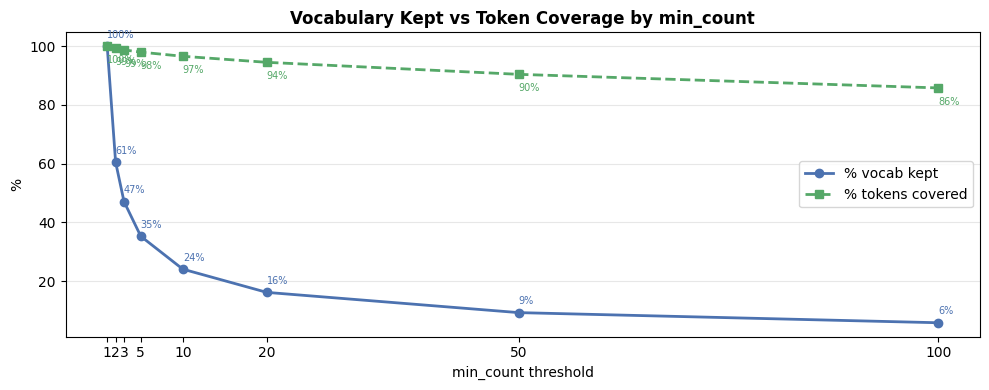

In [25]:
word_counter = Counter()
for text in dataset['text_clean']:
    word_counter.update(text.split())

total_unique = len(word_counter)
total_tokens = sum(word_counter.values())

print(f"VOCABULARY OVERVIEW")
print(f"{'='*40}")
print(f"  Total unique words : {total_unique:,}")
print(f"  Total tokens       : {total_tokens:,}")
print(f"  Avg frequency      : {total_tokens/total_unique:.1f} tokens/word")

thresholds = [1, 2, 3, 5, 10, 20, 50, 100]
kept      = [sum(1 for c in word_counter.values() if c >= t) for t in thresholds]
kept_pct  = [k/total_unique*100 for k in kept]
token_cov = [sum(c for c in word_counter.values() if c >= t)/total_tokens*100 for t in thresholds]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(thresholds, kept_pct,  'o-', color='#4C72B0', label='% vocab kept',      linewidth=2)
ax.plot(thresholds, token_cov, 's--', color='#55A868', label='% tokens covered',  linewidth=2)
ax.set_title('Vocabulary Kept vs Token Coverage by min_count', fontweight='bold')
ax.set_xlabel('min_count threshold')
ax.set_ylabel('%')
ax.set_xticks(thresholds)
ax.legend()
ax.grid(axis='y', alpha=0.3)
for t, kp, tc in zip(thresholds, kept_pct, token_cov):
    ax.annotate(f'{kp:.0f}%', (t, kp), textcoords='offset points',
                xytext=(0, 6), fontsize=7, color='#4C72B0')
    ax.annotate(f'{tc:.0f}%', (t, tc), textcoords='offset points',
                xytext=(0,-12), fontsize=7, color='#55A868')
plt.tight_layout()
plt.show()

# **STEP 1 — Train / Validation / Test Split**

Train: 84,000  Val: 18,000  Test: 18,000
  Train: ['World=21000', 'Sports=21000', 'Business=21000', 'Sci/Tech=21000']
  Val: ['World=4500', 'Sports=4500', 'Business=4500', 'Sci/Tech=4500']
  Test: ['World=4500', 'Sports=4500', 'Business=4500', 'Sci/Tech=4500']


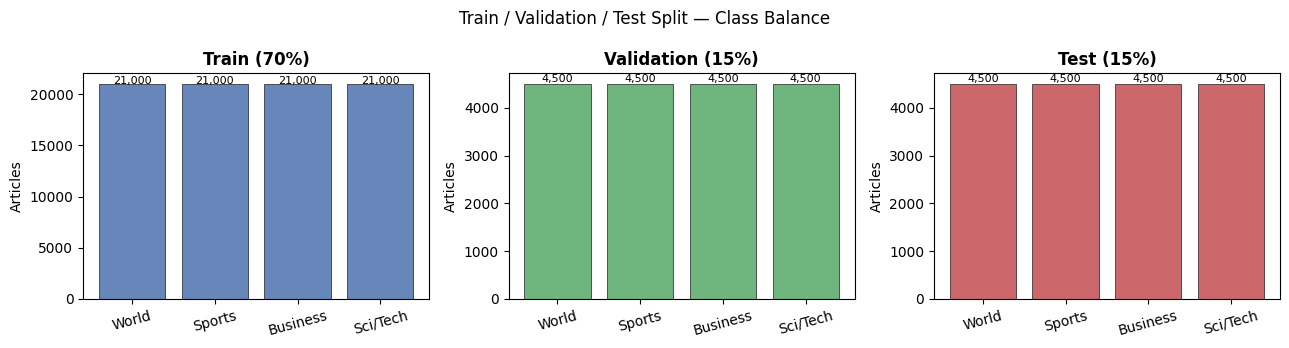

In [ ]:
X = dataset['text_clean'].values
y = dataset['label'].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print(f'Train: {len(y_train):,}  Val: {len(y_val):,}  Test: {len(y_test):,}')
for name, split_y in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    c = Counter(split_y)
    print(f'  {name}: {[f"{CLASS_NAMES[k+1]}={v}" for k, v in sorted(c.items())]}')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (name, split_y), color in zip(
    axes,
    [('Train (70%)', y_train), ('Validation (15%)', y_val), ('Test (15%)', y_test)],
    ['#4C72B0', '#55A868', '#C44E52']
):
    cs   = Counter(split_y)
    cats = [CLASS_NAMES[k+1] for k in sorted(cs.keys())]
    vals = [cs[k] for k in sorted(cs.keys())]
    ax.bar(cats, vals, color=color, edgecolor='black', linewidth=0.5, alpha=0.85)
    ax.set_title(name, fontweight='bold')
    ax.set_ylabel('Articles')
    ax.tick_params(axis='x', rotation=15)
    for i, v in enumerate(vals):
        ax.text(i, v + 50, f'{v:,}', ha='center', fontsize=8)
plt.suptitle('Train / Validation / Test Split — Class Balance', fontsize=12)
plt.tight_layout()
plt.show()

# **STEP 2 — Tokenisation & Padding**

Vocabulary size (MIN_COUNT=5): 25,194
MAX_LEN                                : 150


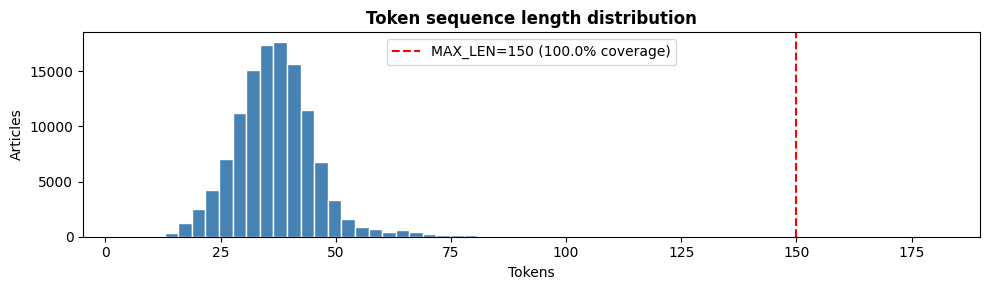

Shapes — train:(84000, 150) val:(18000, 150) test:(18000, 150)


In [ ]:
MIN_COUNT = 5
MAX_LEN   = 150   

tok_full = Tokenizer()
tok_full.fit_on_texts(X_train)

filtered_vocab = {w for w, c in tok_full.word_counts.items() if c >= MIN_COUNT}
tokenizer = Tokenizer(oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)
tokenizer.word_index = {
    w: i+2 for i, w in enumerate(
        sorted(filtered_vocab, key=lambda w: tok_full.word_counts[w], reverse=True)
    )
}
tokenizer.word_index['<OOV>'] = 1
tokenizer.index_word = {i: w for w, i in tokenizer.word_index.items()}

VOCAB_SIZE = len(tokenizer.word_index) + 1
print(f'Vocabulary size (MIN_COUNT={MIN_COUNT}): {VOCAB_SIZE:,}')
print(f'MAX_LEN                                : {MAX_LEN}')

def encode_and_pad(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')

X_train_enc = encode_and_pad(X_train)
X_val_enc   = encode_and_pad(X_val)
X_test_enc  = encode_and_pad(X_test)

seq_lens = dataset['text_clean'].apply(
    lambda t: len(tokenizer.texts_to_sequences([t])[0]))
coverage = (seq_lens <= MAX_LEN).mean() * 100

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(seq_lens.clip(upper=300), bins=60, color='steelblue', edgecolor='white')
ax.axvline(MAX_LEN, color='red', linestyle='--', linewidth=1.5,
           label=f'MAX_LEN={MAX_LEN} ({coverage:.1f}% coverage)')
ax.set_title('Token sequence length distribution', fontweight='bold')
ax.set_xlabel('Tokens'); ax.set_ylabel('Articles')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Shapes — train:{X_train_enc.shape} val:{X_val_enc.shape} test:{X_test_enc.shape}')

# **STEP 3 — Load E1 Embeddings**

In [ ]:
# ══════════════════════════════════════════════════════════════════════════
#  Load embeddings trained in Exercise 1 (.pt PyTorch files)
# ══════════════════════════════════════════════════════════════════════════
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

class _SkipGramModel(nn.Module):
    """Minimal replica of E1 model — only used for loading weights."""
    def __init__(self, vs, ed):
        super().__init__()
        self.W1 = nn.Linear(vs, ed, bias=False)
    def forward(self, t, c):
        pass

def load_pt_to_numpy(path):
    sd = torch.load(path, map_location='cpu')
    sd = {k.replace('_orig_mod.', ''): v for k, v in sd.items()}
    return sd['W1.weight'].T.cpu().numpy()

def align_to_keras_tokenizer(e1_matrix, e1_word2idx, e2_tokenizer,
                              emb_dim, e2_vocab_size):
    matrix = np.zeros((e2_vocab_size, emb_dim), dtype=np.float32)
    found  = 0
    for word, e2_idx in e2_tokenizer.word_index.items():
        if e2_idx >= e2_vocab_size:
            continue
        e1_idx = e1_word2idx.get(word)
        if e1_idx is not None and e1_idx < len(e1_matrix):
            matrix[e2_idx] = e1_matrix[e1_idx]
            found += 1
        else:
            matrix[e2_idx] = np.random.uniform(-0.05, 0.05, emb_dim)
    print(f'  Aligned {found:,}/{len(e2_tokenizer.word_index):,} '
          f'({found/len(e2_tokenizer.word_index)*100:.1f}% coverage)')
    return matrix

# ── Load raw matrices ──────────────────────────────────────────────────────
print('Loading E1 embeddings from .pt files...')
emb1_raw = load_pt_to_numpy('sg_vocab7500_w3_e752_neg2.pt')
emb2_raw = load_pt_to_numpy('sg_vocab5000_w2_e1024_neg1.pt')
print(f'  Emb1 (vocab7500_w3_e752) shape: {emb1_raw.shape}')
print(f'  Emb2 (vocab5000_w2_e1024_neg1) shape: {emb2_raw.shape}')

print('\nReconstructing E1 word2idx...')

STOPWORDS_E1 = {
    'the','a','an','of','in','to','and','for','is','on','at','it','its',
    'with','by','as','be','was','are','that','this','from','have','has',
    'he','she','they','we','or','but','not','will','had','been','were',
    'his','her','their','our','which','who','said','would','also','after',
    'new','more','than','about','up','out','if','one','two','three','four',
    'five','six','seven','all','reuters','ap','afp','says','first','over',
    'quot','fullquote','com'
}

CATEGORY_MAP = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Sci/Tech'}
class_freq = {}
for class_idx, class_name in CATEGORY_MAP.items():
    subset = dataset[dataset['Class Index'] == class_idx]['text_clean']
    freq   = Counter()
    for text in subset:
        freq.update([w for w in text.split()
                     if w not in STOPWORDS_E1 and len(w) > 2])
    class_freq[class_name] = freq

global_freq = Counter()
for freq in class_freq.values():
    global_freq.update(freq)

exclusive_ranked = {cls: [] for cls in class_freq}
for w in global_freq:
    present = [c for c, f in class_freq.items() if f.get(w, 0) > 0]
    if len(present) == 1:
        exclusive_ranked[present[0]].append(w)
exclusive_ranked = {
    cls: sorted(ws, key=lambda w: class_freq[cls][w], reverse=True)
    for cls, ws in exclusive_ranked.items()
}

shared_3plus_ranked = [w for w, _ in global_freq.most_common()
                       if sum(1 for f in class_freq.values()
                              if f.get(w, 0) > 0) >= 3]

def build_vocab_rec(n_exclusive, n_shared):
    vocab = []
    for cls in ['World', 'Sports', 'Business', 'Sci/Tech']:
        vocab.extend(exclusive_ranked[cls][:n_exclusive])
    vocab.extend(shared_3plus_ranked[:n_shared])
    seen = set()
    return [w for w in vocab if not (w in seen or seen.add(w))]

vocab_7500_rec = build_vocab_rec(1500, 2000)
print(f'  vocab7500 reconstructed : {len(vocab_7500_rec):,} words')
if len(vocab_7500_rec) != 7562:
    print(f'  WARNING: mismatch — truncating to 7562')
    vocab_7500_rec = vocab_7500_rec[:7562]

vocab_5000_rec = build_vocab_rec(900, 1400)
print(f'  vocab5000 reconstructed : {len(vocab_5000_rec):,} words')
if len(vocab_5000_rec) != 5001:
    print(f'  WARNING: mismatch — truncating to 5001')
    vocab_5000_rec = vocab_5000_rec[:5001]

E1_WORD2IDX_EMB1 = {w: i+1 for i, w in enumerate(vocab_7500_rec)}
E1_WORD2IDX_EMB2 = {w: i+1 for i, w in enumerate(vocab_5000_rec)}

# ── Align to E2 tokenizer ─────────────────────────────────────────────────
print('\nAligning to E2 tokenizer...')
EMB_DIM_1, EMB_DIM_2 = 752,1024

print('  Embedding 1 (vocab7500_w3_e752_neg2):')
EMB_MATRIX_1 = align_to_keras_tokenizer(
    emb1_raw, E1_WORD2IDX_EMB1, tokenizer, EMB_DIM_1, VOCAB_SIZE)

print('  Embedding 2 (vocab5000_w2_e1024_neg1):')
EMB_MATRIX_2 = align_to_keras_tokenizer(
    emb2_raw, E1_WORD2IDX_EMB2, tokenizer, EMB_DIM_2, VOCAB_SIZE)

EMB_MATRIX_1[0] = 0
EMB_MATRIX_2[0] = 0

print(f'\n  EMB_MATRIX_1: {EMB_MATRIX_1.shape}  (vocab7500_w3_e752)')
print(f'  EMB_MATRIX_2: {EMB_MATRIX_2.shape}  (vocab5000_w2_e1024_neg1)')

Loading E1 embeddings from .pt files...
  Emb1 (vocab7500_w3_e752) shape: (7562, 752)
  Emb2 (vocab5000_w2_e1024_neg1) shape: (5001, 1024)

Reconstructing E1 word2idx...
  vocab7500 reconstructed : 8,000 words
  vocab5000 reconstructed : 5,000 words

Aligning to E2 tokenizer...
  Embedding 1 (vocab7500_w3_e752_neg2):
  Aligned 5,374/25,193 (21.3% coverage)
  Embedding 2 (vocab5000_w2_e1024_neg1):
  Aligned 4,470/25,193 (17.7% coverage)

  EMB_MATRIX_1: (25194, 752)  (vocab7500_w3_e752)
  EMB_MATRIX_2: (25194, 1024)  (vocab5000_w2_e1024_neg1)


# **STEP 4 — Model Architectures**

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

NUM_CLASSES = 4

def get_emb(emb_choice):
    if emb_choice == 'emb1_w3_7500':
        return EMB_MATRIX_1, EMB_DIM_1
    return EMB_MATRIX_2, EMB_DIM_2  


# ══════════════════════════════════════════════════════════════════════════
#  BUILDER 1 — Bidirectional LSTM (BiLSTM)
# ══════════════════════════════════════════════════════════════════════════

def build_bilstm(hp):
    emb_choice = hp.Choice('embedding', ['vocab7500_w3_e752_neg2', 'vocab5000_w2_e1024_neg1'])
    hidden_dim = hp.Choice('hidden_dim', [64, 128])
    num_layers = hp.Int('num_layers', 1, 2)
    lr         = hp.Choice('lr', [1e-3, 5e-4])
    dropout    = hp.Float('dropout', 0.2, 0.4, step=0.1)

    emb_matrix, emb_dim = get_emb(emb_choice)

    inp = keras.Input(shape=(MAX_LEN,), name='input')
    x   = layers.Embedding(
        VOCAB_SIZE, emb_dim,
        weights=[emb_matrix],
        trainable=False,
        mask_zero=True,
        name='embedding'
    )(inp)
    x = layers.Dropout(dropout)(x)

    for i in range(num_layers):
        return_seq = (i < num_layers - 1)
        x = layers.Bidirectional(
            layers.LSTM(hidden_dim,
                        return_sequences=return_seq,
                        dropout=dropout),
            name=f'bilstm_{i}'
        )(x)

    x   = layers.Dense(hidden_dim, activation='relu')(x)
    x   = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax', name='output')(x)

    model = keras.Model(inp, out)
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=lr,
            beta_1=0.9,
            beta_2=0.999,
            clipnorm=1.0
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


# ══════════════════════════════════════════════════════════════════════════
#  BUILDER 2 — GRU
# ══════════════════════════════════════════════════════════════════════════

def build_gru(hp):
    emb_choice = hp.Choice('embedding', ['vocab7500_w3_e752_neg2', 'vocab5000_w2_e1024_neg1'])
    hidden_dim = hp.Choice('hidden_dim', [64, 128])
    num_layers = hp.Int('num_layers', 1, 2)
    lr         = hp.Choice('lr', [3e-3, 1e-3])
    dropout    = hp.Float('dropout', 0.1, 0.3, step=0.1)

    emb_matrix, emb_dim = get_emb(emb_choice)

    inp = keras.Input(shape=(MAX_LEN,), name='input')
    x   = layers.Embedding(
        VOCAB_SIZE, emb_dim,
        weights=[emb_matrix],
        trainable=False,
        mask_zero=True,
        name='embedding'
    )(inp)
    x = layers.Dropout(dropout)(x)

    if num_layers == 2:
        x = layers.Bidirectional(
            layers.LSTM(hidden_dim, return_sequences=True, dropout=dropout),
            name='bilstm_0'
        )(x)
        x = layers.Bidirectional(
            layers.GRU(hidden_dim, dropout=dropout),
            name='gru_0'
        )(x)
    else:
        x = layers.Bidirectional(
            layers.GRU(hidden_dim, dropout=dropout),
            name='gru_0'
        )(x)

    x   = layers.Dense(hidden_dim, activation='relu')(x)
    x   = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax', name='output')(x)

    model = keras.Model(inp, out)
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=lr,
            beta_1=0.9,
            beta_2=0.999
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


# ══════════════════════════════════════════════════════════════════════════
#  BUILDER 3 — Transformer + BiGRU (optional)
# ══════════════════════════════════════════════════════════════════════════


def build_transformer(hp):
    emb_choice = hp.Choice('embedding', ['vocab7500_w3_e752_neg2', 'vocab5000_w2_e1024_neg1'])
    num_heads  = hp.Choice('num_heads', [2, 4])
    hidden_dim = hp.Choice('hidden_dim', [64, 128])
    lr         = hp.Choice('lr', [1e-3, 5e-4])
    dropout    = hp.Float('dropout', 0.1, 0.2, step=0.1)

    emb_matrix, emb_dim = get_emb(emb_choice)

    attention_layer = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=64
    )

    inp = keras.Input(shape=(MAX_LEN,), name='input')
    x   = layers.Embedding(
        VOCAB_SIZE, emb_dim,
        weights=[emb_matrix],
        trainable=False,
        mask_zero=True,
        name='embedding'
    )(inp)

    x = layers.Lambda(lambda z: attention_layer(z, z), name='mha')(x)
    x = layers.Dropout(dropout)(x)
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    x = layers.Bidirectional(
        layers.GRU(hidden_dim, dropout=dropout),
        name='bigru'
    )(x)

    x   = layers.Dense(hidden_dim, activation='relu')(x)
    x   = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax', name='output')(x)

    model = keras.Model(inp, out)
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=lr,
            beta_1=0.9,
            beta_2=0.999
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# **STEP 5 — Keras Tuner **

In [30]:
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

SEARCH_EPOCHS = 8
BATCH_SIZE    = 256

search_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=3, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, verbose=0
    )
]

tuners = {}

for arch_name, builder in [
    ('BiLSTM',      build_bilstm),
    ('GRU',         build_gru),
    ('Transformer', build_transformer),
]:
    print(f'\n{"="*60}')
    print(f'  Keras Tuner — Hyperband — {arch_name}')
    print(f'{"="*60}')

    tuner = kt.Hyperband(
        builder,
        objective='val_accuracy',
        max_epochs=SEARCH_EPOCHS,
        factor=3,
        seed=SEED,
        directory='kt_results',
        project_name=arch_name,
        overwrite=True
    )

    tuner.search(
        X_train_enc, y_train,
        validation_data=(X_val_enc, y_val),
        batch_size=BATCH_SIZE,
        callbacks=search_callbacks,
        verbose=1
    )

    tuners[arch_name] = tuner

    print(f'\nTop-3 configs for {arch_name}:')
    for i, hp in enumerate(tuner.get_best_hyperparameters(3), 1):
        print(f'  Rank {i}: {hp.values}')

print('\n✓ Hyperparameter search complete for all 3 architectures')

Trial 10 Complete [00h 01m 17s]
val_accuracy: 0.6805555820465088

Best val_accuracy So Far: 0.7181110978126526
Total elapsed time: 00h 08m 26s

Top-3 configs for Transformer:
  Rank 1: {'embedding': 'vocab5000_w2_e1024_neg1', 'num_heads': 4, 'hidden_dim': 64, 'lr': 0.001, 'dropout': 0.2, 'tuner/epochs': 8, 'tuner/initial_epoch': 0, 'tuner/bracket': 0, 'tuner/round': 0}
  Rank 2: {'embedding': 'vocab7500_w3_e752_neg2', 'num_heads': 4, 'hidden_dim': 64, 'lr': 0.001, 'dropout': 0.1, 'tuner/epochs': 8, 'tuner/initial_epoch': 3, 'tuner/bracket': 1, 'tuner/round': 1, 'tuner/trial_id': '0001'}
  Rank 3: {'embedding': 'vocab7500_w3_e752_neg2', 'num_heads': 2, 'hidden_dim': 128, 'lr': 0.001, 'dropout': 0.2, 'tuner/epochs': 8, 'tuner/initial_epoch': 0, 'tuner/bracket': 0, 'tuner/round': 0}

✓ Hyperparameter search complete for all 3 architectures


HYPERBAND SEARCH RESULTS — All completed trials
           Arch   Emb  Hidden Layers      LR  Val Acc
1           GRU  Emb2      64      2  0.0030   0.8809
2           GRU  Emb2     128      1  0.0030   0.8781
3           GRU  Emb2      64      1  0.0030   0.8778
4           GRU  Emb2      64      2  0.0030   0.8769
5           GRU  Emb2     128      1  0.0030   0.8740
6           GRU  Emb2      64      1  0.0030   0.8644
7        BiLSTM  Emb2     128      1  0.0010   0.8637
8           GRU  Emb2     128      1  0.0030   0.8629
9        BiLSTM  Emb2     128      2  0.0005   0.8628
10       BiLSTM  Emb2     128      1  0.0010   0.8628
11       BiLSTM  Emb2     128      1  0.0010   0.8624
12          GRU  Emb2     128      2  0.0030   0.8594
13          GRU  Emb2      64      1  0.0030   0.8585
14       BiLSTM  Emb2      64      2  0.0010   0.8576
15          GRU  Emb2     128      2  0.0010   0.8492
16       BiLSTM  Emb2     128      1  0.0010   0.8428
17       BiLSTM  Emb2     128     

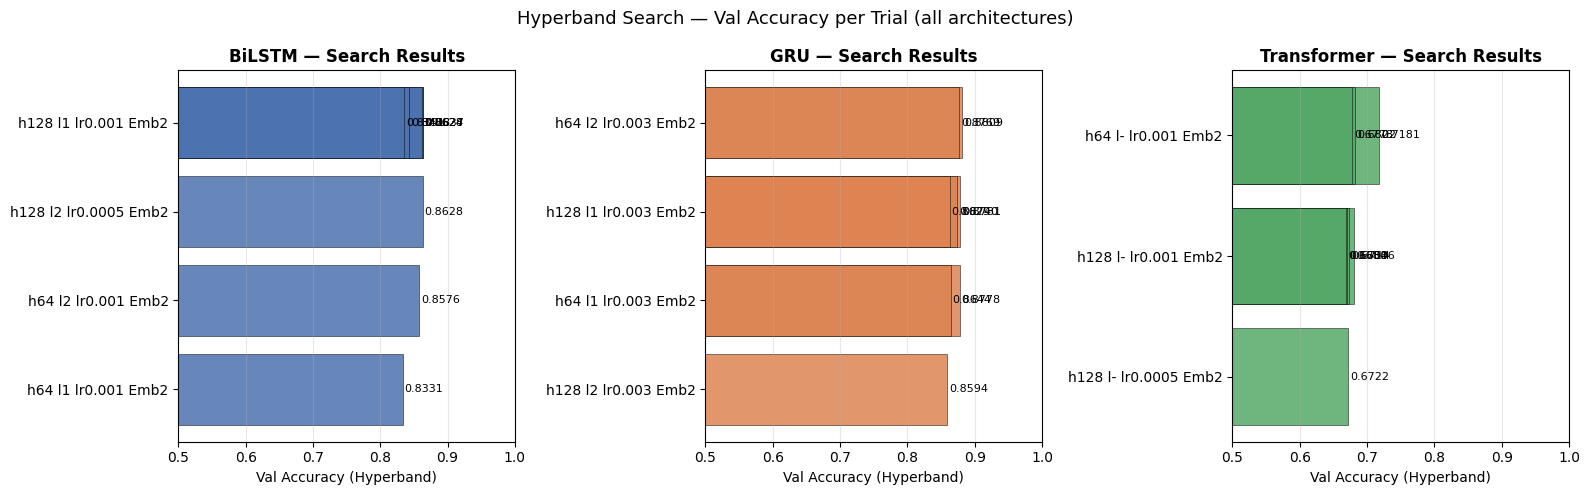

In [31]:
# ══════════════════════════════════════════════════════════════════════════
#  Hyperband Search Results — Val accuracy per trial
# ══════════════════════════════════════════════════════════════════════════

search_records = []
for arch_name, tuner in tuners.items():
    for trial in tuner.oracle.trials.values():
        if trial.status != 'COMPLETED':
            continue
        hp    = trial.hyperparameters.values
        score = trial.score if trial.score else 0.0
        search_records.append({
            'Arch':    arch_name,
            'Emb':     'Emb1' if hp.get('embedding','').startswith('emb1') else 'Emb2',
            'Hidden':  hp.get('hidden_dim', hp.get('num_heads', '-')),
            'Layers':  hp.get('num_layers', '-'),
            'LR':      hp.get('lr', '-'),
            'Val Acc': round(score, 4),
        })

df_search = (pd.DataFrame(search_records)
             .sort_values('Val Acc', ascending=False)
             .reset_index(drop=True))
df_search.index += 1

print('HYPERBAND SEARCH RESULTS — All completed trials')
print('=' * 60)
print(df_search.to_string())

# ── Visualisation ──────────────────────────────────────────────────────────
arch_colors = {'BiLSTM': '#4C72B0', 'GRU': '#DD8452', 'Transformer': '#55A868'}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, arch in zip(axes, ['BiLSTM', 'GRU', 'Transformer']):
    subset = (df_search[df_search['Arch'] == arch]
              .head(8)
              .reset_index(drop=True))

    labels = [f"h{r['Hidden']} l{r['Layers']} lr{r['LR']} {r['Emb']}"
              for _, r in subset.iterrows()]

    bars = ax.barh(labels, subset['Val Acc'],
                   color=arch_colors[arch],
                   edgecolor='black', linewidth=0.4, alpha=0.85)
    ax.set_title(f'{arch} — Search Results', fontweight='bold')
    ax.set_xlabel('Val Accuracy (Hyperband)')
    ax.invert_yaxis()
    ax.set_xlim(0.5, 1.0)
    ax.grid(axis='x', alpha=0.3)

    for bar, val in zip(bars, subset['Val Acc']):
        ax.text(bar.get_width() + 0.003,
                bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=8)

plt.suptitle('Hyperband Search — Val Accuracy per Trial (all architectures)',
             fontsize=13)
plt.tight_layout()
plt.show()

# **STEP 6 — Full Training with Best Hyperparameters**

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

FULL_EPOCHS = 50
best_models = {}
all_histories = {}

full_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',          
        patience=6,
        restore_best_weights=True,  
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',         
        factor=0.5,
        patience=4,
        min_lr=1e-7,               
        verbose=1
    )
]

for arch_name, tuner in tuners.items():
    print(f'\n{"="*55}')
    print(f'  Full training — {arch_name}')
    print(f'{"="*55}')

    best_hp    = tuner.get_best_hyperparameters(1)[0]
    best_model = tuner.hypermodel.build(best_hp)
    best_model.summary()

    history = best_model.fit(
        X_train_enc, y_train,
        validation_data=(X_val_enc, y_val),
        epochs=FULL_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=full_callbacks,
        verbose=1
    )

    best_models[arch_name]   = best_model
    all_histories[arch_name] = history
    print(f'  Best val_accuracy: {max(history.history["val_accuracy"]):.4f}')

print('\n✓ Full training complete')


  Full training — BiLSTM


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 150)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 1024) │ 25,798,656 │ input[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 150, 1024) │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 150)       │          0 │ input[0][0]       │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_0            │ (None, 256)       │  1,180,672 │ dropout_3[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ bilstm_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 4)         │        516 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 27,012,740 (103.05 MB)

 Trainable params: 1,214,084 (4.63 MB)

 Non-trainable params: 25,798,656 (98.41 MB)

... (10 outputs left out)

 Total params: 26,227,780 (100.05 MB)

 Trainable params: 429,124 (1.64 MB)

 Non-trainable params: 25,798,656 (98.41 MB)

Epoch 1/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.4830 - loss: 1.1756 - val_accuracy: 0.5366 - val_loss: 1.1003 - learning_rate: 0.0010
Epoch 2/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.6043 - loss: 0.9807 - val_accuracy: 0.6415 - val_loss: 0.9062 - learning_rate: 0.0010
Epoch 3/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.6267 - loss: 0.9323 - val_accuracy: 0.6439 - val_loss: 0.8889 - learning_rate: 0.0010
Epoch 4/50
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6374 - loss: 0.9090
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.6432 - loss: 0.8950 - val_accuracy: 0.6797 - val_loss: 0.8228 - learning_rate: 0.0010
Epoch 5/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.6621 - loss: 0.8565 - val_accuracy: 0.6875 - val_loss: 0.7973 - learning_rate: 5.0000e-04
Epoch 6/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.6707 - loss

Training curves — loss and accuracy for all architectures

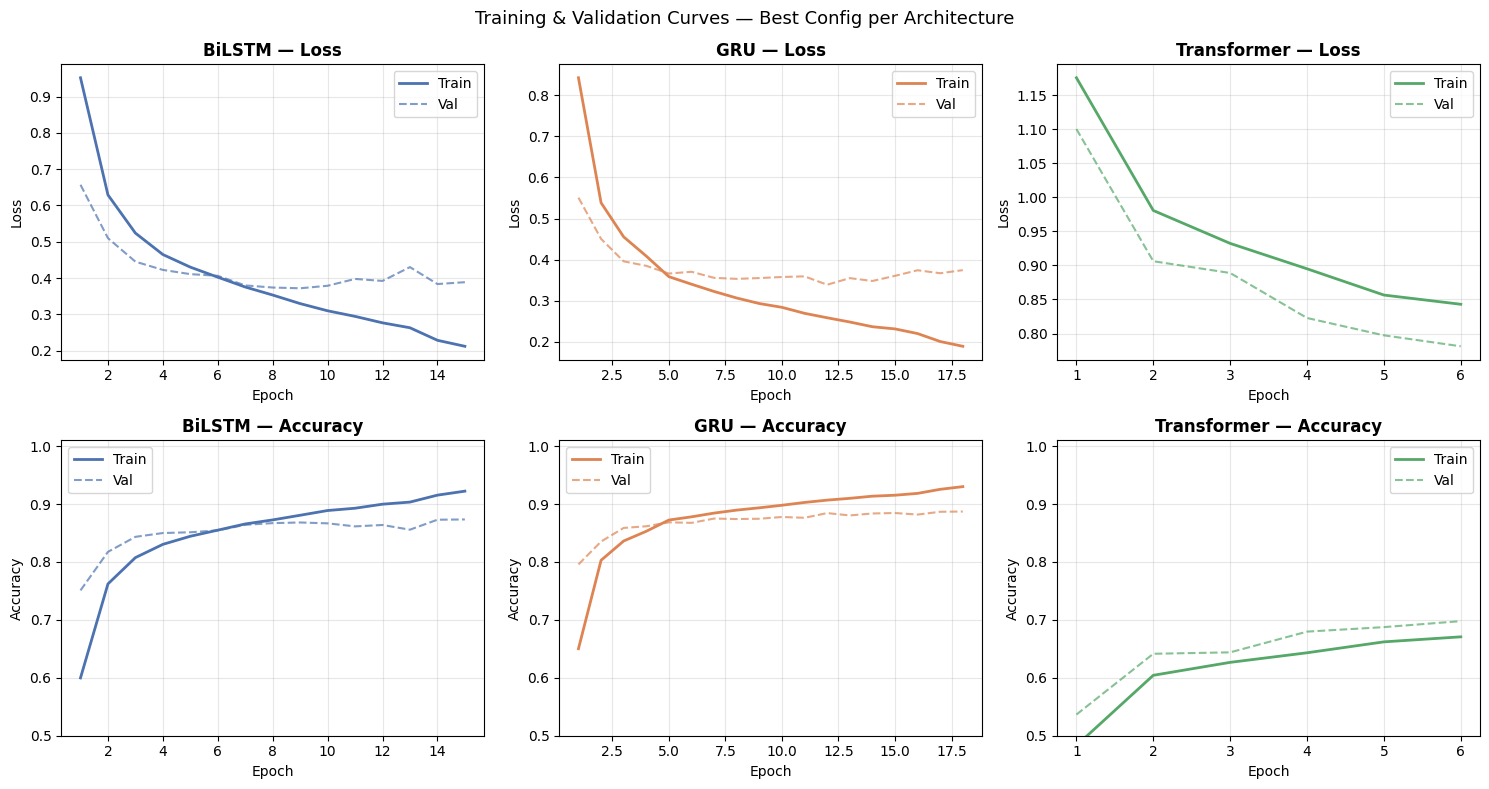

In [ ]:
PALETTE = ['#4C72B0', '#DD8452', '#55A868']
arch_names = list(all_histories.keys())
fig, axes = plt.subplots(2, len(arch_names), figsize=(15, 8))

for col, (arch_name, history) in enumerate(all_histories.items()):
    color = PALETTE[col]
    ep    = range(1, len(history.history['loss']) + 1)

    ax_l = axes[0][col]
    ax_a = axes[1][col]

    ax_l.plot(ep, history.history['loss'],     '-',  color=color, lw=2, label='Train')
    ax_l.plot(ep, history.history['val_loss'], '--', color=color, lw=1.5, alpha=0.7, label='Val')
    ax_l.set_title(f'{arch_name} — Loss', fontweight='bold')
    ax_l.set_xlabel('Epoch'); ax_l.set_ylabel('Loss')
    ax_l.legend(); ax_l.grid(alpha=0.3)

    ax_a.plot(ep, history.history['accuracy'],     '-',  color=color, lw=2, label='Train')
    ax_a.plot(ep, history.history['val_accuracy'], '--', color=color, lw=1.5, alpha=0.7, label='Val')
    ax_a.set_title(f'{arch_name} — Accuracy', fontweight='bold')
    ax_a.set_xlabel('Epoch'); ax_a.set_ylabel('Accuracy')
    ax_a.set_ylim(0.5, 1.01)
    ax_a.legend(); ax_a.grid(alpha=0.3)

plt.suptitle('Training & Validation Curves — Best Config per Architecture',
             fontsize=13)
plt.tight_layout()
plt.show()

# **STEP 7 — Evaluation**

In [34]:
# ── Test set evaluation for all architectures ──────────────────────────────
test_results = []

for arch_name, model in best_models.items():
    y_pred = np.argmax(model.predict(X_test_enc, batch_size=512, verbose=0), axis=1)

    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='macro')
    pre = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_test, y_pred, average='macro')
    trainable = sum(np.prod(w.shape) for w in model.trainable_weights)

    test_results.append({
        'Architecture':     arch_name,
        'Test Acc':         round(acc, 4),
        'Macro F1':         round(f1,  4),
        'Precision':        round(pre, 4),
        'Recall':           round(rec, 4),
        'Trainable params': trainable,
    })

    print(f'\n{arch_name} — Classification Report (Test Set)')
    print('='*60)
    print(classification_report(
        y_test, y_pred, target_names=list(CLASS_NAMES.values()), digits=4))

df_test = (pd.DataFrame(test_results)
           .sort_values('Test Acc', ascending=False)
           .reset_index(drop=True))
df_test.index += 1
print('\nFINAL TEST RESULTS')
print('='*65)
print(df_test.to_string())

BEST_ARCH = df_test.iloc[0]['Architecture']


BiLSTM — Classification Report (Test Set)
              precision    recall  f1-score   support

       World     0.8413    0.8880    0.8640      4500
      Sports     0.9216    0.9380    0.9297      4500
    Business     0.8875    0.7784    0.8294      4500
    Sci/Tech     0.8245    0.8653    0.8444      4500

    accuracy                         0.8674     18000
   macro avg     0.8687    0.8674    0.8669     18000
weighted avg     0.8687    0.8674    0.8669     18000


GRU — Classification Report (Test Set)
              precision    recall  f1-score   support

       World     0.8882    0.8807    0.8844      4500
      Sports     0.9406    0.9433    0.9420      4500
    Business     0.8551    0.8500    0.8526      4500
    Sci/Tech     0.8537    0.8636    0.8586      4500

    accuracy                         0.8844     18000
   macro avg     0.8844    0.8844    0.8844     18000
weighted avg     0.8844    0.8844    0.8844     18000



/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'mha' (of type Lambda) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(



Transformer — Classification Report (Test Set)
              precision    recall  f1-score   support

       World     0.6475    0.5049    0.5674      4500
      Sports     0.7720    0.3951    0.5227      4500
    Business     0.4099    0.8471    0.5525      4500
    Sci/Tech     0.6278    0.4029    0.4908      4500

    accuracy                         0.5375     18000
   macro avg     0.6143    0.5375    0.5333     18000
weighted avg     0.6143    0.5375    0.5333     18000


FINAL TEST RESULTS
  Architecture  Test Acc  Macro F1  Precision  Recall  Trainable params
1          GRU    0.8844    0.8844     0.8844  0.8844            640580
2       BiLSTM    0.8674    0.8669     0.8687  0.8674           1214084
3  Transformer    0.5375    0.5333     0.6143  0.5375            429124


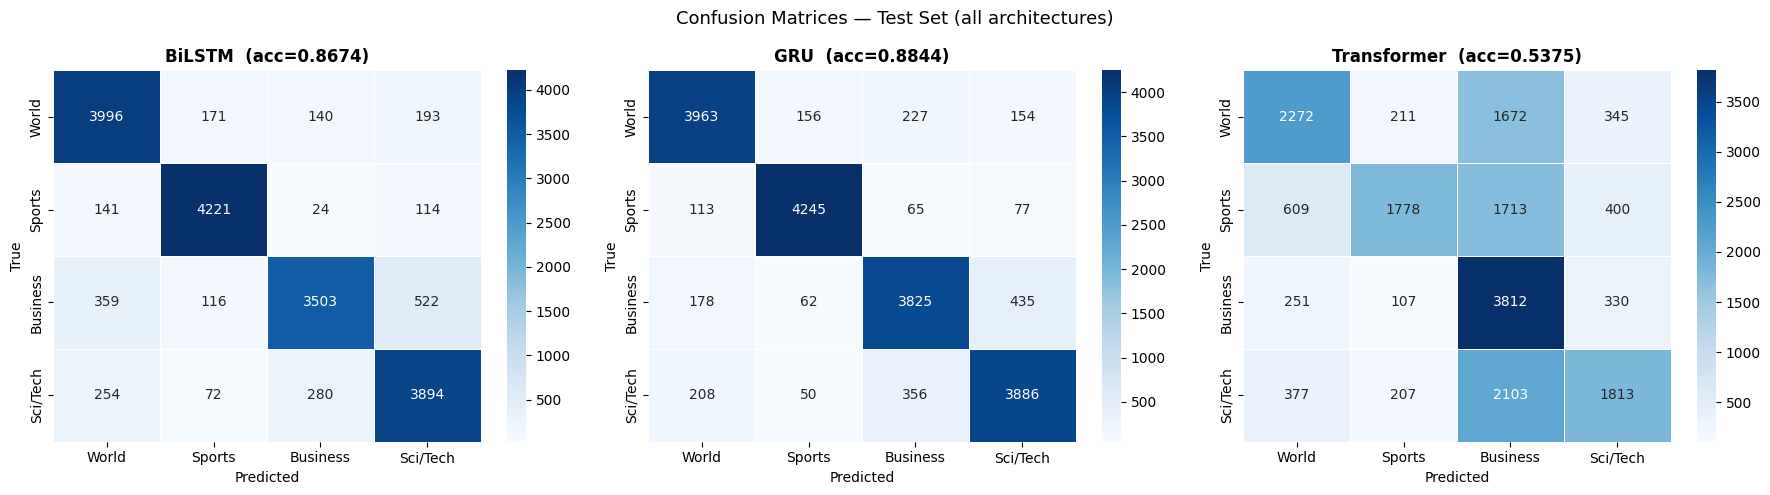

In [35]:
# ── Confusion matrices ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, len(best_models), figsize=(18, 5))

for col, (arch_name, model) in enumerate(best_models.items()):
    y_pred = np.argmax(model.predict(X_test_enc, batch_size=512, verbose=0), axis=1)
    cm     = confusion_matrix(y_test, y_pred)
    acc    = accuracy_score(y_test, y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=list(CLASS_NAMES.values()),
                yticklabels=list(CLASS_NAMES.values()),
                linewidths=0.5, linecolor='white',
                ax=axes[col], annot_kws={'size': 10})
    axes[col].set_title(f'{arch_name}  (acc={acc:.4f})', fontweight='bold')
    axes[col].set_xlabel('Predicted')
    axes[col].set_ylabel('True')

plt.suptitle('Confusion Matrices — Test Set (all architectures)', fontsize=13)
plt.tight_layout()
plt.show()

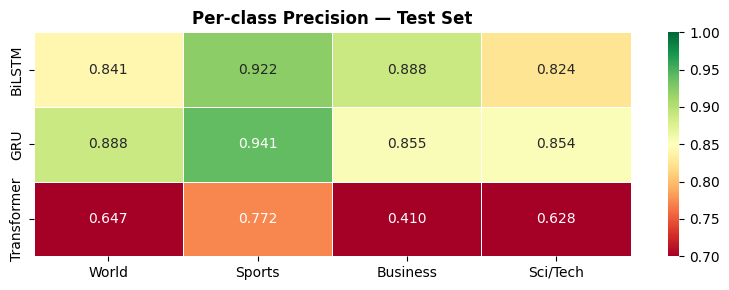

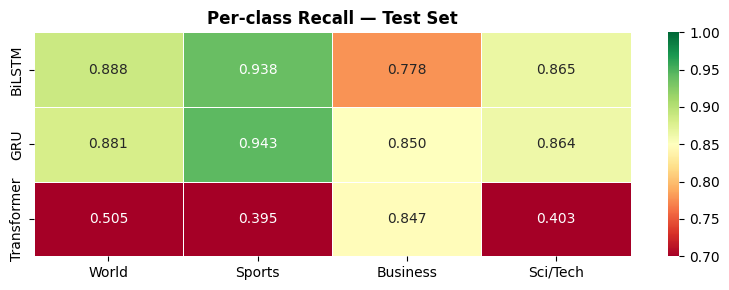

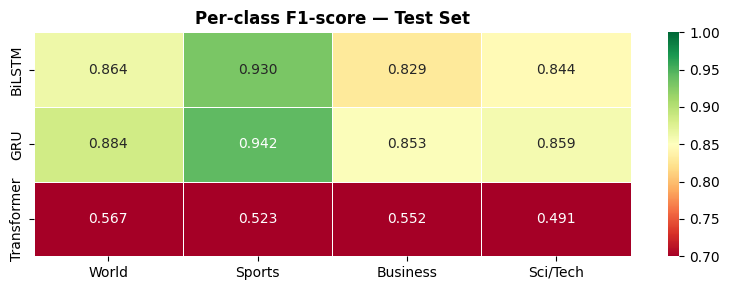

In [36]:
# ── Per-class precision / recall / F1 heatmaps ────────────────────────────
classes    = list(CLASS_NAMES.values())
arch_names = list(best_models.keys())

for metric in ['precision', 'recall', 'f1-score']:
    mat = []
    for arch_name, model in best_models.items():
        y_pred = np.argmax(model.predict(X_test_enc, batch_size=512, verbose=0), axis=1)
        report = classification_report(
            y_test, y_pred, target_names=classes, output_dict=True)
        mat.append([report[c][metric] for c in classes])

    fig, ax = plt.subplots(figsize=(8, 3))
    sns.heatmap(np.array(mat), annot=True, fmt='.3f',
                cmap='RdYlGn', vmin=0.7, vmax=1.0,
                xticklabels=classes, yticklabels=arch_names,
                linewidths=0.4, linecolor='white', ax=ax,
                annot_kws={'size': 10})
    ax.set_title(f'Per-class {metric.capitalize()} — Test Set', fontweight='bold')
    plt.tight_layout()
    plt.show()

Embedding comparison (best val acc per arch + embedding):
Embedding    Emb1 (vocab7500, w3, dim=752)  Emb2 (vocab5000, w2, dim=1024)
Arch                                                                      
BiLSTM                              0.8637                          0.8624
GRU                                 0.8809                          0.8781
Transformer                         0.6822                          0.7181


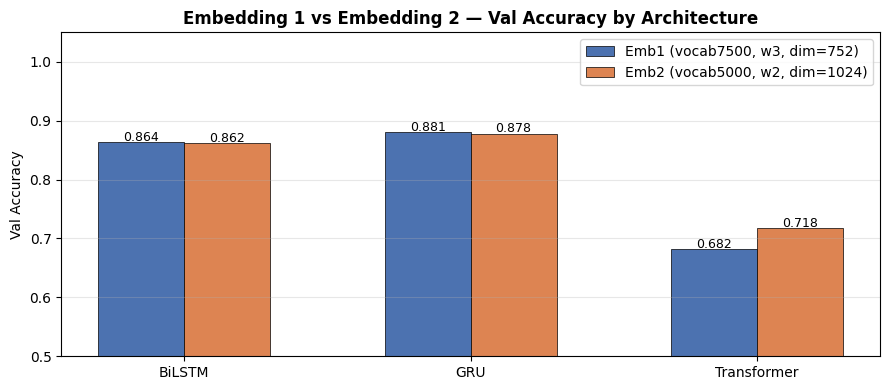

In [37]:
# ── Embedding comparison ──────────────────────────────
emb_compare = []
for arch_name, tuner in tuners.items():
    for emb_key, emb_label in [
        ('vocab7500_w3_e752_neg2',   'Emb1 (vocab7500, w3, dim=752)'),
        ('vocab5000_w2_e1024_neg1',  'Emb2 (vocab5000, w2, dim=1024)')
    ]:
        best_score = 0.0
        for trial in tuner.oracle.trials.values():
            if trial.status != 'COMPLETED': continue
            if trial.hyperparameters.values.get('embedding') == emb_key:
                if trial.score and trial.score > best_score:
                    best_score = trial.score
        emb_compare.append({'Arch': arch_name, 'Embedding': emb_label,
                             'Val Acc': round(best_score, 4)})

df_emb = pd.DataFrame(emb_compare)
pivot  = df_emb.pivot(index='Arch', columns='Embedding', values='Val Acc')
print('Embedding comparison (best val acc per arch + embedding):')
print(pivot.to_string())

x     = np.arange(len(pivot))
width = 0.3
fig, ax = plt.subplots(figsize=(9, 4))
for i, (col, color) in enumerate(zip(pivot.columns, ['#4C72B0', '#DD8452'])):
    bars = ax.bar(x + (i-0.5)*width, pivot[col].values, width,
                  label=col, color=color, edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, pivot[col].values):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                f'{val:.3f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(pivot.index)
ax.set_ylim(0.5, 1.05)
ax.set_title('Embedding 1 vs Embedding 2 — Val Accuracy by Architecture', fontweight='bold')
ax.set_ylabel('Val Accuracy')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# **STEP 9 — Custom Test Set (20 news snippets)**

In [38]:
# 20 manually sourced news snippets (5 per class)
# Sourced from BBC, Reuters, AP (May 2025). Balanced across 4 categories.


CUSTOM_TEST = [
    # World (0)
    ('UN Security Council raises alarm over North Korea nuclear and ballistic missile programme',    0),
    ('EU designates seven countries as safe to speed up asylum procedures amid migration pressure',  0),
    ('Ukraine ceasefire talks resume in Turkey as Russia and Western powers seek diplomatic solution', 0),
    ('G7 foreign ministers demand North Korea abandon nuclear weapons programme',                    0),
    ('Brazil Amazon deforestation falls to lowest level in over a decade following government enforcement', 0),
    # Sports (1)
    ('Liverpool clinch record-equalling 20th Premier League title in Arne Slot first season as manager', 1),
    ('Oklahoma City Thunder win first NBA title defeating Indiana Pacers in seven-game Finals series', 1),
    ('Jannik Sinner defeats Carlos Alcaraz to win first Wimbledon title in four-set final',          1),
    ('Philadelphia Eagles demolish Kansas City Chiefs 40-22 to win Super Bowl LIX in New Orleans',   1),
    ('World Athletics Championships Tokyo 2025 USA dominates as Shacarri Richardson leads sprint relay to gold', 1),
    # Business (2)
    ('Federal Reserve holds interest rates steady at 4.25 to 4.5 percent amid trade policy uncertainty', 2),
    ('Oil prices rise as OPEC extends production cuts to support global crude market',               2),
    ('Tesla China-made EV sales rise as Model Y demand grows in China and Europe markets',           2),
    ('Amazon pushes deeper into physical grocery stores opening mega-store to rival Walmart and Costco', 2),
    ('Wall Street declines as bond yields climb following stronger than expected US jobs report',    2),
    # Sci/Tech (3)
    ('OpenAI launches GPT-4.5 its largest and most knowledgeable model with improved emotional intelligence', 3),
    ('NASA lunar reconnaissance orbiter finds water ice deposits more widespread than previously thought near south pole', 3),
    ('Scientists develop solid-state battery capable of charging to full capacity in under two minutes', 3),
    ('Apple expected to unveil next generation Vision Pro headset with lighter design and improved battery life', 3),
    ('CRISPR gene editing therapy shows complete remission in sickle cell disease patients in clinical trial', 3),
]

custom_texts  = [t for t, _ in CUSTOM_TEST]
custom_labels = np.array([l for _, l in CUSTOM_TEST])
custom_clean  = [text.lower().translate(str.maketrans('', '', string.punctuation))
                 for text in custom_texts]
custom_enc    = encode_and_pad(custom_clean)

best_m    = best_models[BEST_ARCH]
cust_pred = np.argmax(best_m.predict(custom_enc, verbose=0), axis=1)
cust_acc  = accuracy_score(custom_labels, cust_pred)

print(f'Best model    : {BEST_ARCH}')
print(f'Custom test   : {cust_acc:.4f}  ({int(cust_acc*20)}/20 correct)\n')
print(f'  {"Text":<68}  {"True":<10}  {"Pred":<10}  OK')
print('  ' + '─'*95)
for text, true_l, pred_l in zip(custom_texts, custom_labels, cust_pred):
    ok = '✓' if true_l == pred_l else '✗'
    print(f'  {text[:68]:<68}  '
          f'{CLASS_NAMES[true_l+1]:<10}  '
          f'{CLASS_NAMES[pred_l+1]:<10}  {ok}')

Best model    : GRU
Custom test   : 0.9000  (18/20 correct)

  Text                                                                  True        Pred        OK
  ───────────────────────────────────────────────────────────────────────────────────────────────
  UN Security Council raises alarm over North Korea nuclear and ballis  World       World       ✓
  EU designates seven countries as safe to speed up asylum procedures   World       World       ✓
  Ukraine ceasefire talks resume in Turkey as Russia and Western power  World       World       ✓
  G7 foreign ministers demand North Korea abandon nuclear weapons prog  World       World       ✓
  Brazil Amazon deforestation falls to lowest level in over a decade f  World       World       ✓
  Liverpool clinch record-equalling 20th Premier League title in Arne   Sports      Sports      ✓
  Oklahoma City Thunder win first NBA title defeating Indiana Pacers i  Sports      Sports      ✓
  Jannik Sinner defeats Carlos Alcaraz to win first Wimb

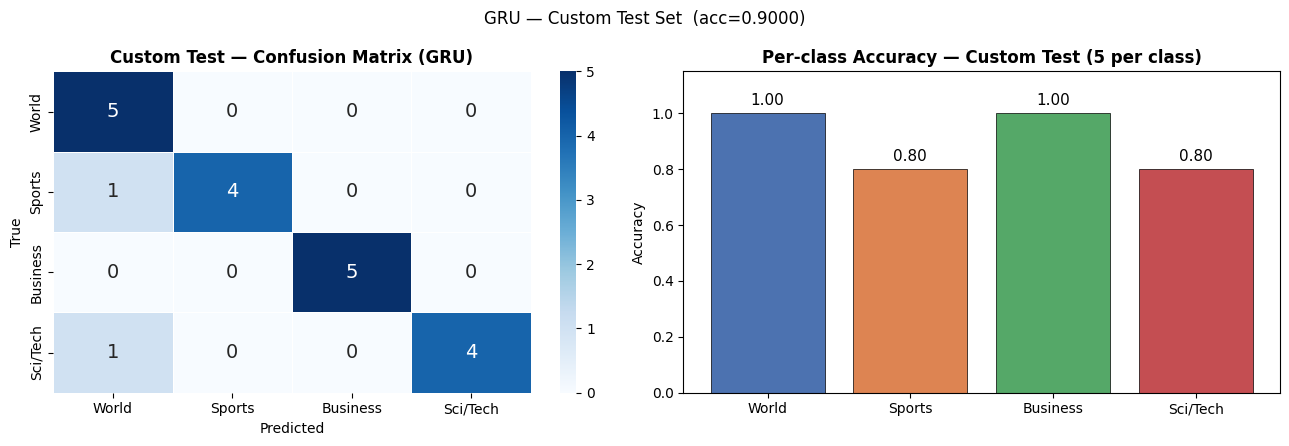

In [39]:
cm_custom = confusion_matrix(custom_labels, cust_pred)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.heatmap(cm_custom, annot=True, fmt='d', cmap='Blues',
            xticklabels=list(CLASS_NAMES.values()),
            yticklabels=list(CLASS_NAMES.values()),
            linewidths=0.5, linecolor='white', ax=axes[0],
            annot_kws={'size': 14})
axes[0].set_title(f'Custom Test — Confusion Matrix ({BEST_ARCH})', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

per_class = [cm_custom[i,i]/cm_custom[i].sum() if cm_custom[i].sum() > 0 else 0
             for i in range(4)]
bars = axes[1].bar(list(CLASS_NAMES.values()), per_class,
                   color=COLORS, edgecolor='black', linewidth=0.5)
axes[1].set_title('Per-class Accuracy — Custom Test (5 per class)', fontweight='bold')
axes[1].set_ylabel('Accuracy'); axes[1].set_ylim(0, 1.15)
for bar, val in zip(bars, per_class):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.03,
                 f'{val:.2f}', ha='center', fontsize=11)

plt.suptitle(f'{BEST_ARCH} — Custom Test Set  (acc={cust_acc:.4f})', fontsize=12)
plt.tight_layout()
plt.show()

# **STEP 10 — Final Ranking & Overfitting Analysis**

FINAL MODEL RANKING
  Architecture  Test Acc  Macro F1  Precision  Recall  Trainable params
1          GRU    0.8844    0.8844     0.8844  0.8844            640580
2       BiLSTM    0.8674    0.8669     0.8687  0.8674           1214084
3  Transformer    0.5375    0.5333     0.6143  0.5375            429124


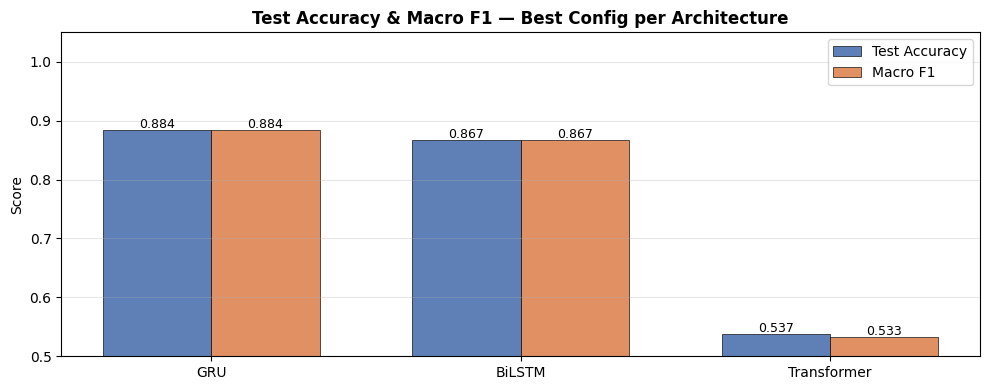


OVERFITTING ANALYSIS
  BiLSTM          train=0.9223  val=0.8734  gap=+0.0489  best_val=0.8734 (ep15)  [OK]
  GRU             train=0.9301  val=0.8871  gap=+0.0430  best_val=0.8871 (ep18)  [OK]
  Transformer     train=0.6707  val=0.6978  gap=-0.0271  best_val=0.6978 (ep6)  [OK]


In [40]:
print('FINAL MODEL RANKING')
print('='*65)
print(df_test.to_string())

x     = np.arange(len(df_test))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 4))
b1 = ax.bar(x - width/2, df_test['Test Acc'], width, label='Test Accuracy',
            color='#4C72B0', edgecolor='black', linewidth=0.5, alpha=0.9)
b2 = ax.bar(x + width/2, df_test['Macro F1'], width, label='Macro F1',
            color='#DD8452', edgecolor='black', linewidth=0.5, alpha=0.9)
for bar, val in list(zip(b1, df_test['Test Acc'])) + list(zip(b2, df_test['Macro F1'])):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.003,
            f'{val:.3f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(df_test['Architecture'])
ax.set_ylim(0.5, 1.05)
ax.set_title('Test Accuracy & Macro F1 — Best Config per Architecture', fontweight='bold')
ax.set_ylabel('Score')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print('\nOVERFITTING ANALYSIS')
print('='*65)
for arch_name, history in all_histories.items():
    tr  = history.history['accuracy'][-1]
    val = history.history['val_accuracy'][-1]
    bv  = max(history.history['val_accuracy'])
    ep  = history.history['val_accuracy'].index(bv) + 1
    gap = tr - val
    status = 'OVERFIT' if gap > 0.05 else 'OK'
    print(f'  {arch_name:<15} train={tr:.4f}  val={val:.4f}  '
          f'gap={gap:+.4f}  best_val={bv:.4f} (ep{ep})  [{status}]')

In [41]:
# Save best model weights + architecture (.keras format)
best_model = best_models[BEST_ARCH]
best_model.save(f"{BEST_ARCH}_best_model.keras")
print(f"Trained model saved → {BEST_ARCH}_best_model.keras")

Trained model saved → GRU_best_model.keras


In [42]:
import json

# Save model architecture as JSON (no weights, structure only)
model_config = best_model.get_config()
config_path = f"{BEST_ARCH}_model_config.json"

with open(config_path, "w") as f:
    json.dump(model_config, f, indent=2)

print(f"Model config saved → {config_path}")

Model config saved → GRU_model_config.json
